# 기계학습 회귀(Regression)란 무엇인가?

- 회귀(Regression)는 **연속적인 수치 데이터를 예측**하는 머신러닝 문제
- 예측하고자 하는 목표값(Target)이 실수일 때 사용

예
- 중고차 데이터에서 **가격** 을 예측하고자 할때
- 기상, 미세먼지 데이터에서 **평균기온** 이나  **미세먼지 농도** 를 예측하고자 할 때
- 주택의 면적과 위치로 **집값** 을 예측하고자 할 때
- 체중, 키, 나이로 **혈압** 을 예측하고자 할 때


---

## 분류(Classification)와 회귀(Regression)의 차이

| 항목 | 분류 (Classification) | 회귀 (Regression) |
|------|------------------------|--------------------|
| 예측값 | 범주형 (class) | 연속형 (숫자) |
| 예시 | '암 여부', '품종', '주의보', '경보' 등 | 기온, 미세먼지농도, 중고차가격, 혈압 등 |
| 목적 | 어떤 클래스(그룹)에 속하는가? | 수치를 얼마나 잘예측하는가? |
| 모델 평가 | 정확도, 정밀도, 재현율,F1-score 등  | MAE, RMSE, R² 등 |
| 예측 결과 | 클래스 이름 (또는 확률) | 실수(float) |


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
plt.rc('font', family = 'Malgun Gothic')
plt.rc('axes', unicode_minus = False)

### 중고차 관련 캐글에 있는 'car.csv' 파일을 읽어 df에 지정

In [3]:
df = pd.read_csv('car.csv')
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2018,10600,Manual,27380,Petrol,145,56.5,1.0
1,Fiesta,2018,11000,Manual,7724,Petrol,145,65.7,1.0
2,Fiesta,2014,7291,Manual,23894,Petrol,30,54.3,1.2
3,Fiesta,2014,6998,Manual,20325,Petrol,30,54.3,1.2
4,Fiesta,2018,11800,Manual,34671,Petrol,145,65.7,1.0


| 열 이름 | 설명 |
|---------|------|
| model | 차량 모델명 |
| year | 연식 |
| price | **판매 가격 (예측 대상)** |
| transmission | 변속기 종류 |
| mileage | 주행거리 (mile) |
| fuelType | 연료 종류 |
| tax | 세금 (유로) |
| mpg | 연비 (mile per gallon) |
| engineSize | 엔진 크기 (리터) |


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         1372 non-null   str    
 1   year          1372 non-null   int64  
 2   price         1372 non-null   int64  
 3   transmission  1372 non-null   str    
 4   mileage       1372 non-null   int64  
 5   fuelType      1372 non-null   str    
 6   tax           1372 non-null   int64  
 7   mpg           1372 non-null   float64
 8   engineSize    1372 non-null   float64
dtypes: float64(2), int64(4), str(3)
memory usage: 122.4 KB


In [5]:
df.describe(include = 'all')

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
count,1372,1372.000000,1372.000000,1372,1372.000000,1372,1372.00000,1372.000000,1372.000000
unique,1,NaN,NaN,3,NaN,2,NaN,NaN,NaN
top,Fiesta,NaN,NaN,Manual,NaN,Petrol,NaN,NaN,NaN
freq,1372,NaN,NaN,1270,NaN,1299,NaN,NaN,NaN
mean,NaN,2016.870262,10246.741254,NaN,21615.703353,NaN,101.62172,60.831050,1.093659
std,NaN,2.286373,2871.141723,NaN,16195.652603,NaN,64.20709,7.603176,0.183083
min,NaN,2004.000000,1295.000000,NaN,5.000000,NaN,0.00000,40.300000,0.000000
25%,NaN,2016.000000,8399.750000,NaN,10235.250000,NaN,20.00000,54.300000,1.000000
50%,NaN,2017.000000,9998.000000,NaN,17611.500000,NaN,145.00000,62.800000,1.000000
75%,NaN,2018.000000,11888.250000,NaN,28849.250000,NaN,145.00000,65.700000,1.200000


In [6]:
df['model'].unique()

<ArrowStringArray>
[' Fiesta']
Length: 1, dtype: str

### 'transmission' 열에 value_counts() 적용

<Axes: xlabel='transmission'>

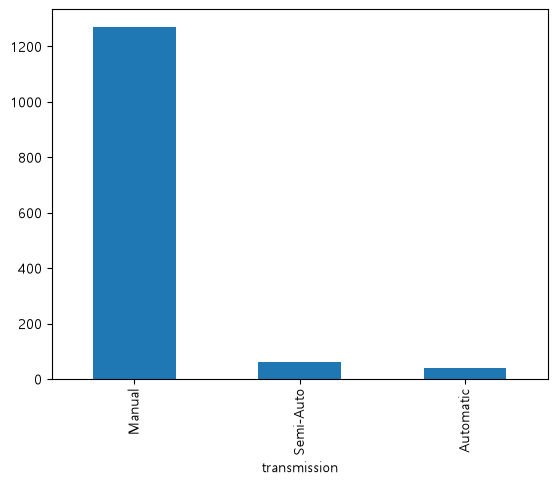

In [9]:
df['transmission'].value_counts().plot(kind = 'bar')

### 'fuelType' 열에 value_counts() 적용

In [10]:
df['fuelType'].value_counts()

fuelType
Petrol    1299
Diesel      73
Name: count, dtype: int64

<Axes: xlabel='fuelType', ylabel='count'>

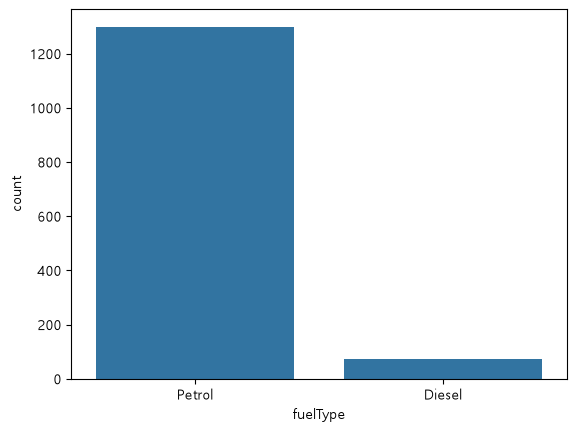

In [12]:
sns.countplot(data = df, x = 'fuelType')

### 기계학습에서  X (특성)는 숫자 데이터로만 가능합니다!

### 수치형 변수들 간 상관관계

In [13]:
df.columns

Index(['model', 'year', 'price', 'transmission', 'mileage', 'fuelType', 'tax',
       'mpg', 'engineSize'],
      dtype='str')

In [15]:
corr = df[['price', 'year', 'mileage', 'tax', 'mpg', 'engineSize']].corr().round(2)
corr

,price,year,mileage,tax,mpg,engineSize
price,1.00,0.68,-0.71,0.46,-0.18,-0.21
year,0.68,1.00,-0.60,0.43,0.00,-0.25
mileage,-0.71,-0.60,1.00,-0.33,0.04,0.29
tax,0.46,0.43,-0.33,1.00,-0.38,0.04
mpg,-0.18,0.00,0.04,-0.38,1.00,-0.18
engineSize,-0.21,-0.25,0.29,0.04,-0.18,1.00


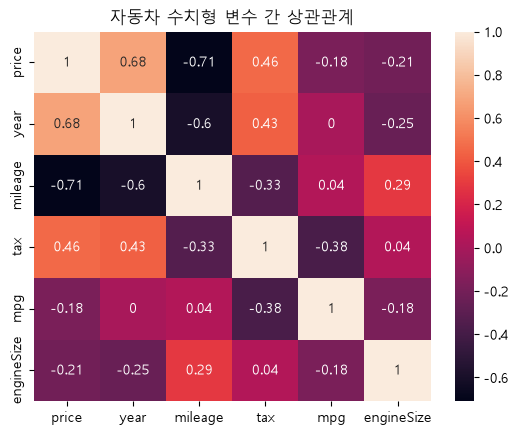

In [17]:
sns.heatmap(corr, annot = True)
plt.title('자동차 수치형 변수 간 상관관계')
plt.show()

### X (특성) , y (예측할 대상, 타겟) 지정

In [ ]:
# df[['price', 'year', 'mileage', 'tax', 'mpg', 'engineSize']]

In [18]:
X = df[['year', 'mileage', 'tax', 'mpg', 'engineSize']]
y = df['price']

### 학습/테스트 분할

In [19]:
from sklearn.model_selection import train_test_split

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

## 선형 회귀모델 학습

![선형회귀](linear-regressor.png)

## 참고: 선형 회귀 수식

선형 회귀는 다음과 같은 수식으로 구성됨

$$
\hat{y} = w_1 x_1 + w_2 x_2 + \cdots + w_n x_n + b
$$

예를 들어 자동차 가격 예측에서는 다음과 같이 해석할 수 있음

$$
\text{예측 가격} = w_1 \cdot \text{연식} + w_2 \cdot \text{주행거리} + w_3 \cdot \text{연비} + w_4 \cdot \text{엔진크기} + b
$$

- $ \hat{y} $: 예측된 가격
- $ x_i $: 입력 변수 (연식, 주행거리 등)
- $ w_i $: 각 변수의 가중치 (기울기)
- $ b $: 절편 (bias)

In [21]:
from sklearn.linear_model import LinearRegression

In [23]:
# sklearn 모델 출력 인코딩 에러 방지
import sklearn
sklearn.set_config(display='text')

In [24]:
lr = LinearRegression()
lr

LinearRegression()

In [25]:
lr.fit(X_train, y_train)

LinearRegression()

In [26]:
y_pred = lr.predict(X_test)
y_pred

array([12130.21577263,  7408.67624807,  7480.68613245, 10413.67106174,
       13014.46997988,  9911.89571032,  9755.79841017, 10906.38622628,
       10781.68936867,  7484.63407081, 13264.24997805, 13124.05202505,
       10664.01486799, 10619.87785547,  7707.3833193 , 10090.95571152,
        6602.41034254, 10501.48357334, 10057.88698005, 12061.83066295,
       11950.67912053, 11534.54570344,  9042.77782673, 11860.99071523,
       11940.43854016, 11137.23986989,  8728.81279402,  8741.77918374,
       10733.17515918, 10657.85009613,  8283.81918297, 10244.97125213,
       13027.36912361, 11938.17212182, 13646.1980799 ,  9598.10589974,
       11325.11383974,  2040.60179143, 11160.67552336,  7789.45844289,
        7681.18037144, 11576.95857558, 13486.33407674,  8346.00065068,
        7283.42566006,  8753.79202945, 12138.63233481, 12657.42854   ,
        9479.29997559, 10511.95254505,  6289.59478165, 11919.23210409,
       10362.77532806, 12760.81790017,  9885.76003201, -1624.02179836,
      

##  회귀 모델 평가 지표

분류 모델은 "정확도(Accuracy)"로 평가했습니다.  
회귀 모델은 **예측값과 실제값의 차이(오차)** 로 평가합니다.



###  세 가지 주요 지표

**① MAE (Mean Absolute Error, 평균 절대 오차)**

$$\text{MAE} = \frac{1}{n}\sum|y_i - \hat{y}_i|$$

- 오차의 절댓값 평균
- **단위가 원래 데이터와 같음** → 해석이 직관적
- 예: MAE = £2,000 → "평균적으로 실제 가격과 £2,000 차이"

---

**② RMSE (Root Mean Squared Error, 평균 제곱근 오차)**

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum(y_i - \hat{y}_i)^2}$$

- 오차를 제곱한 뒤 평균 → 루트
- **큰 오차에 더 민감** (제곱 때문)
- 보통 MAE보다 값이 큼

---

**③ R² (결정 계수, R-squared)**

$$R^2 = 1 - \frac{\sum(y_i - \hat{y}_i)^2}{\sum(y_i - \bar{y})^2}$$

- 0 ~ 1 사이 값 (1에 가까울수록 좋음)
- **"이 모델이 가격 변동의 몇 %를 설명하는가"** 를 나타냄
- 예: R² = 0.85 → 가격 변동의 85%를 이 모델이 설명

| 지표 | 작을수록? 클수록? | 단위 | 직관 |
|------|-----------------|------|------|
| MAE  | 작을수록 좋음 | 원래 단위(£) | 평균 오차 |
| RMSE | 작을수록 좋음 | 원래 단위(£) | 큰 오차에 민감 |
| R²   | **클수록** 좋음 | 없음 (0~1) | 설명력 |

## 성능 평가 및 해석

In [28]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'평균절대오차 (MAE) : {mae : .2f}')
print(f'평균제곱근오차 (RMSE) : {rmse : .2f}')
print(f'R2 Score: {r2 : .2f}')

평균절대오차 (MAE) :  1193.15
평균제곱근오차 (RMSE) :  1580.91
R2 Score:  0.69


## 실제값 vs 예측값 시각화

In [29]:
y_pred

array([12130.21577263,  7408.67624807,  7480.68613245, 10413.67106174,
       13014.46997988,  9911.89571032,  9755.79841017, 10906.38622628,
       10781.68936867,  7484.63407081, 13264.24997805, 13124.05202505,
       10664.01486799, 10619.87785547,  7707.3833193 , 10090.95571152,
        6602.41034254, 10501.48357334, 10057.88698005, 12061.83066295,
       11950.67912053, 11534.54570344,  9042.77782673, 11860.99071523,
       11940.43854016, 11137.23986989,  8728.81279402,  8741.77918374,
       10733.17515918, 10657.85009613,  8283.81918297, 10244.97125213,
       13027.36912361, 11938.17212182, 13646.1980799 ,  9598.10589974,
       11325.11383974,  2040.60179143, 11160.67552336,  7789.45844289,
        7681.18037144, 11576.95857558, 13486.33407674,  8346.00065068,
        7283.42566006,  8753.79202945, 12138.63233481, 12657.42854   ,
        9479.29997559, 10511.95254505,  6289.59478165, 11919.23210409,
       10362.77532806, 12760.81790017,  9885.76003201, -1624.02179836,
      

In [30]:
y_test

1023    10597
642      5499
1196     7980
31      10495
253     15999
        ...  
1342    12400
251     10795
1256     8750
966      7599
1096     6498
Name: price, Length: 275, dtype: int64

In [31]:
y_test.values

array([10597,  5499,  7980, 10495, 15999, 12500,  9795, 12000,  9999,
        6000, 16690, 16491,  8250, 10990,  7500, 11287,  6500, 10000,
        8510, 11998, 12600, 11479,  7790, 12495, 11200,  8491,  8998,
        7499,  7485, 11500,  7999, 11295, 16299, 11900, 13750,  8600,
        9600,  2998,  7295,  7250,  7999, 11291, 13199,  9495,  4999,
        6250, 10900, 12750,  9250,  9851,  5995, 11260,  9750, 13998,
        9100,  1295,  9680, 13299,  8500, 13998, 12391, 11170, 11885,
       11200,  5998,  6991, 11998, 10250, 10750,  9995,  8998, 11200,
        6897,  8250,  9998, 14000,  8240, 12500,  9900, 12299,  7749,
        5600,  7000, 12000, 12000, 11250, 14299, 12999, 10450, 14290,
        9600,  7960, 12495, 10298, 11440, 10998, 10950,  8000, 17500,
        8990, 10495, 19000, 12450, 11800, 15695, 14999, 10299, 10298,
        8189, 11150,  9741, 10497,  8998,  7739, 10500,  5490, 13100,
        9710,  9000,  8497, 10990, 12489, 11498, 12500,  8991, 15500,
       12495, 10475,

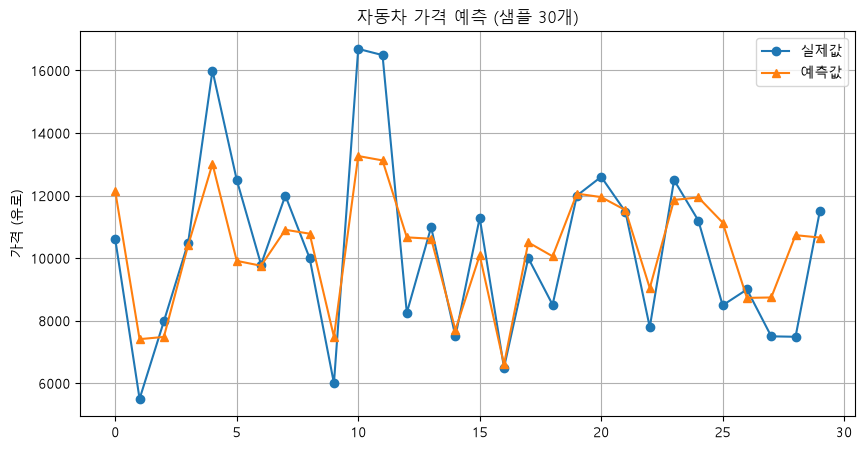

In [37]:
plt.figure(figsize = (10, 5))
plt.plot(y_test.values[:30], label = '실제값', marker = 'o')
plt.plot(y_pred[:30], label = '예측값', marker = '^')
plt.title('자동차 가격 예측 (샘플 30개)')
plt.ylabel('가격 (유로)')
plt.legend()
plt.grid()
plt.show()


## 회귀 모델 비교


| 모델 | 특징 |
|------|------|
| **LinearRegression** | 기본 선형 회귀 |
| **KNeighborsRegressor** | 가까운 k개 이웃 값의 **평균**으로 예측 |
| **DecisionTreeRegressor** | 분기를 반복해 리프 노드 데이터의 **평균**으로 예측 |
| **RandomForestRegressor** | 여러 결정 트리의 평균 → 비선형 관계도 포착 |



### 분류에서 이미 배운 모델 — 회귀에서는 어떻게 다를까?

**KNN 분류 vs KNN 회귀**  

```
분류 KNN:  이웃 3명 → [고급차, 고급차, 저가차] → 다수결  → "고급차"
회귀 KNN:  이웃 3명 → [£15000, £18000, £12000] → 평균   → £15000
```

**결정 트리 분류 vs 결정 트리 회귀**

```
분류 DT:  리프 노드 도달 → 가장 많은 클래스  → "고급차"
회귀 DT:  리프 노드 도달 → 데이터들의 평균  → £22,500
```

**랜덤 포레스트 분류 vs 랜덤 포레스트 회귀**

```
분류 RF:  여러 결정트리들이 각각 클래스 예측 → 투표(voting) → 가장 많이 나온 클래스 선택 → "고급차"
회귀 RF:  여러 결정트리들이 각각 숫자 예측 → 평균값 계산 → £23,100
```

> **핵심**: 알고리즘 구조는 같고, **마지막 출력 단계만** 다수결 → **평균**으로 바뀝니다!


**DecisionTreeRegressor의 주의점: max_depth**  
깊이 제한 없이 학습하면 훈련 데이터에만 딱 맞는 **과적합(Overfitting)** 발생  
`max_depth` 로 나무 깊이를 제한해 과적합을 막을 수 있습니다.

In [38]:
from sklearn.neighbors import KNeighborsRegressor

In [39]:
from sklearn.preprocessing import StandardScaler

In [40]:
X_train

,year,mileage,tax,mpg,engineSize
1326,2018,21191,145,65.7,1.0
1109,2016,21832,20,62.8,1.0
1139,2018,16035,145,65.7,1.0
657,2017,6273,0,57.7,1.0
704,2018,22727,145,56.5,1.0
...,...,...,...,...,...
763,2017,6229,145,65.7,1.0
835,2014,46321,30,54.3,1.2
1216,2019,12362,145,60.1,1.0
559,2016,19764,0,65.7,1.0


In [41]:
scaler = StandardScaler()

In [43]:
X_train_scaled = scaler.fit_transform(X_train)
X_train_scaled

array([[ 0.47871979, -0.03129896,  0.67881171,  0.61846289, -0.53157503],
       [-0.3744981 ,  0.00856467, -1.27177621,  0.24251639, -0.53157503],
       [ 0.47871979, -0.35194933,  0.67881171,  0.61846289, -0.53157503],
       ...,
       [ 0.90532874, -0.5803723 ,  0.67881171, -0.10750276, -0.53157503],
       [-0.3744981 , -0.12004374, -1.58387028,  0.61846289, -0.53157503],
       [ 0.05211085, -0.50748591,  0.67881171,  0.61846289, -0.53157503]],
      shape=(1097, 5))

In [45]:
X_test_scaled = scaler.transform(X_test)
X_test_scaled

array([[ 4.78719793e-01, -9.98225250e-01,  6.78811710e-01,
         4.24007802e-01,  1.45770117e-03],
       [-2.50754283e+00,  8.32952040e-01,  6.78811710e-01,
        -1.58536139e+00,  1.60055588e+00],
       [-3.74498100e-01,  1.29838016e+00, -1.58387028e+00,
         6.18462886e-01, -5.31575026e-01],
       ...,
       [ 4.78719793e-01,  1.77285470e-01,  6.78811710e-01,
         6.18462886e-01, -5.31575026e-01],
       [ 5.21108467e-02, -4.64450596e-01,  3.66717642e-01,
        -8.59395747e-01,  5.34490428e-01],
       [-8.01107046e-01,  1.08662404e+00, -1.58387028e+00,
         6.18462886e-01, -5.31575026e-01]], shape=(275, 5))

In [47]:
knn = KNeighborsRegressor(n_neighbors = 5)
knn

KNeighborsRegressor()

In [48]:
knn.fit(X_train_scaled, y_train)

KNeighborsRegressor()

In [49]:
y_pred = knn.predict(X_test_scaled)
y_pred

array([10454.6,  6209.2,  7703. , 10465.6, 15502.6, 10949.6,  9948.4,
       10714.8, 11330. ,  6278.6, 18383. , 14969. , 10068. , 10732. ,
        9236.6, 12182.8,  7197.2,  9948.4,  9649.6, 11956.2, 12311.8,
       10935.6,  8964.4, 11502. , 11797.8,  9499.2,  9116. ,  7877. ,
        8047.8, 10758.8,  7737.8, 11922. , 15956.8, 12894. , 14798. ,
        8791.8,  9263. ,  3566. ,  8810.2,  7729.8,  8375.4, 11247.8,
       12809.8,  9510.4,  7370. ,  7013. , 10454.6, 13860. , 10614.4,
        9548.4,  6182.6, 11735.8,  9343. , 13371.6,  9859.4,  2675. ,
       10076.6, 11414.6,  9793.8, 13971.8, 11049.2, 14717.4, 11502. ,
       11459. ,  6313. ,  7428. , 10714.8,  9099.4, 11049.2, 10554. ,
        8728. , 12152. ,  7757.2,  8876. , 11148. , 12807.8,  8051.2,
       10890. , 10481.4, 12869.6,  6993. ,  5100.6,  6782.8, 11770. ,
        9907.6, 11275.4, 13319.8, 13699.8,  9804.2, 15826.6,  9515.8,
        8147.6, 11247.8, 10196.2, 12813.2, 10465.6, 11193.8,  8523.6,
       18383. ,  952

In [51]:
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'평균절대오차 (MAE): {mae:.2f}')
print(f'평균제곱근오차 (RMSE): {rmse:.2f}')
print(f'R2 Score: {r2:.2f}')

평균절대오차 (MAE): 754.95
평균제곱근오차 (RMSE): 970.77
R2 Score: 0.88


In [52]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

In [53]:
dt = DecisionTreeRegressor(max_depth = 3, random_state = 0)
dt

DecisionTreeRegressor(max_depth=3, random_state=0)

In [54]:
dt.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=3, random_state=0)

In [55]:
y_pred = dt.predict(X_test)
y_pred

array([11199.32014388,  3516.95238095,  8451.74299065, 11199.32014388,
       14342.51219512,  9697.69366197,  8451.74299065,  9697.69366197,
       11199.32014388,  6789.25225225, 18351.44444444, 14342.51219512,
        9697.69366197, 11199.32014388,  6789.25225225,  9697.69366197,
        6789.25225225,  9697.69366197,  8451.74299065, 14342.51219512,
       14342.51219512, 11199.32014388,  9697.69366197, 11199.32014388,
       11199.32014388, 11199.32014388,  8451.74299065,  6789.25225225,
        8451.74299065,  9697.69366197,  6789.25225225, 11199.32014388,
       14342.51219512, 11199.32014388, 14342.51219512,  9697.69366197,
       11199.32014388,  3516.95238095,  9697.69366197,  8451.74299065,
        8451.74299065, 11199.32014388, 14342.51219512,  8451.74299065,
        6789.25225225,  8451.74299065, 11199.32014388, 11199.32014388,
        9697.69366197,  9697.69366197,  6789.25225225, 11199.32014388,
        9697.69366197, 14342.51219512,  8451.74299065,  3516.95238095,
      

In [57]:
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'평균절대오차 (MAE): {mae:.2f}')
print(f'평균제곱근오차 (RMSE): {rmse:.2f}')
print(f'R2 Score: {r2:.2f}')

평균절대오차 (MAE): 1144.21
평균제곱근오차 (RMSE): 1401.92
R2 Score: 0.76


In [58]:
rf = RandomForestRegressor(random_state = 0)
rf

RandomForestRegressor(random_state=0)

In [59]:
rf.fit(X_train, y_train)

RandomForestRegressor(random_state=0)

In [60]:
y_pred = rf.predict(X_test)

In [75]:
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'평균절대오차 (MAE): {mae:.2f}')
print(f'평균제곱근오차 (RMSE): {rmse:.2f}')
print(f'R2 Score: {r2:.2f}')

평균절대오차 (MAE): 747.61
평균제곱근오차 (RMSE): 971.52
R2 Score: 0.88


## 중고자동차 가격 예측 회귀모델 (범주형 변수 포함 확장)

- **자동차 가격을 예측** 하기 위한 회귀 모델을 학습 
- 수치형 변수뿐 아니라, **문자열로 되어 있는 범주형 변수**(`transmission`, `fuelType`)도 함께 사용

비교하는 모델:
- KNN Regressor
- Decision Tree Regressor
- Random Forest Regressor

## 전 처리 및 범주형 변수 인코딩

- car.csv에는 `transmission`, `fuelType`처럼 문자열로 된 **범주형 변수(categorical variable)** 가 있음
- 이러한 변수는 회귀모델이 직접 처리할 수 없기 때문에, 수치형으로 변환해야 해요!! 
- **One-Hot Encoding (원-핫 인코딩)** 이 가장 널리 사용되는 방법

### One-Hot Encoding이란?
- 각 범주(카타고리)를 0 또는 1로 표시하는 더미(dummy) 변수로 변환
- 예: `transmission`이 "Manual", "Automatic", "Semi-Auto" => 
  `transmission_Manual`, `transmission_Automatic`, `transmission_Semi-Auto` 열 생성

In [76]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         1372 non-null   str    
 1   year          1372 non-null   int64  
 2   price         1372 non-null   int64  
 3   transmission  1372 non-null   str    
 4   mileage       1372 non-null   int64  
 5   fuelType      1372 non-null   str    
 6   tax           1372 non-null   int64  
 7   mpg           1372 non-null   float64
 8   engineSize    1372 non-null   float64
dtypes: float64(2), int64(4), str(3)
memory usage: 122.4 KB


In [77]:
X

,year,mileage,tax,mpg,engineSize,transmission_Automatic,transmission_Manual,transmission_Semi-Auto,fuelType_Diesel,fuelType_Petrol
0,2018,27380,145,56.5,1.0,False,True,False,False,True
1,2018,7724,145,65.7,1.0,False,True,False,False,True
2,2014,23894,30,54.3,1.2,False,True,False,False,True
3,2014,20325,30,54.3,1.2,False,True,False,False,True
4,2018,34671,145,65.7,1.0,False,True,False,False,True
...,...,...,...,...,...,...,...,...,...,...
1367,2014,50000,0,65.7,1.0,False,True,False,False,True
1368,2016,30900,0,65.7,1.0,False,True,False,False,True
1369,2018,431,145,48.7,1.0,True,False,False,False,True
1370,2017,31597,0,57.7,1.0,True,False,False,False,True


In [78]:
df.columns

Index(['model', 'year', 'price', 'transmission', 'mileage', 'fuelType', 'tax',
       'mpg', 'engineSize'],
      dtype='str')

In [79]:
df['transmission'].value_counts()

transmission
Manual       1270
Semi-Auto      62
Automatic      40
Name: count, dtype: int64

In [80]:
df['fuelType'].value_counts()

fuelType
Petrol    1299
Diesel      73
Name: count, dtype: int64

In [81]:
X=df[['year', 'mileage', 'tax', 'mpg', 'engineSize', 'transmission', 'fuelType']]

In [82]:
X = pd.get_dummies(X)
y = df['price']

In [85]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

In [86]:
rf = RandomForestRegressor(random_state = 0)

In [87]:
rf.fit(X_train, y_train)

RandomForestRegressor(random_state=0)

In [88]:
y_pred = rf.predict(X_test)

In [91]:
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'평균절대오차 (MAE): {mae:.2f}')
print(f'평균제곱근오차 (RMSE): {rmse:.2f}')
print(f'R2 Score: {r2:.2f}')

평균절대오차 (MAE): 747.61
평균제곱근오차 (RMSE): 971.52
R2 Score: 0.88


#### 과제: DecisionTreeRegressor ,KNeighborsRegressor 사용하여 각각 학습하고 성능평가지표를 구해보세요

In [94]:
dt = DecisionTreeRegressor(max_depth = 3, random_state = 0)
dt

DecisionTreeRegressor(max_depth=3, random_state=0)

In [96]:
dt.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=3, random_state=0)

In [97]:
y_pred = dt.predict(X_test)
y_pred

array([11199.32014388,  3516.95238095,  8451.74299065, 11199.32014388,
       14342.51219512,  9697.69366197,  8451.74299065,  9697.69366197,
       11199.32014388,  6789.25225225, 18351.44444444, 14342.51219512,
        9697.69366197, 11199.32014388,  6789.25225225,  9697.69366197,
        6789.25225225,  9697.69366197,  8451.74299065, 14342.51219512,
       14342.51219512, 11199.32014388,  9697.69366197, 11199.32014388,
       11199.32014388, 11199.32014388,  8451.74299065,  6789.25225225,
        8451.74299065,  9697.69366197,  6789.25225225, 11199.32014388,
       14342.51219512, 11199.32014388, 14342.51219512,  9697.69366197,
       11199.32014388,  3516.95238095,  9697.69366197,  8451.74299065,
        8451.74299065, 11199.32014388, 14342.51219512,  8451.74299065,
        6789.25225225,  8451.74299065, 11199.32014388, 11199.32014388,
        9697.69366197,  9697.69366197,  6789.25225225, 11199.32014388,
        9697.69366197, 14342.51219512,  8451.74299065,  3516.95238095,
      

In [107]:
mae_dt = mean_absolute_error(y_test, y_pred)
rmse_dt = root_mean_squared_error(y_test, y_pred)
r2_dt = r2_score(y_test, y_pred)

print(f'평균절대오차 (MAE) : {mae_dt : .2f}')
print(f'평균제곱근오차 (RMSE) : {rmse_dt : .2f}')
print(f'R2 Score : {r2_dt : .2f}')

평균절대오차 (MAE) :  1144.21
평균제곱근오차 (RMSE) :  1401.92
R2 Score :  0.76


In [111]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [113]:
knn = KNeighborsRegressor(n_neighbors = 5)
knn.fit(X_train_scaled, y_train)

KNeighborsRegressor()

In [115]:
y_pred = knn.predict(X_test_scaled)
y_pred

array([10454.6,  6510. ,  7703. , 10465.6, 15502.6, 11347.6,  9948.4,
       10714.8, 11330. ,  6278.6, 18383. , 14969. , 10068. , 10732. ,
        9954.6, 12182.8,  7197.2,  9948.4,  9649.6, 11956.2, 12311.8,
       10935.6,  8964.4, 11502. , 11797.8,  9499.2,  9116. ,  7877. ,
        8047.8, 10758.8,  7737.8, 11922. , 15808.8, 12894. , 14798. ,
        8791.8,  9263. ,  3566. ,  8810.2,  7729.8,  8375.4, 11247.8,
       12809.8, 10031.4,  7430. ,  7013. , 10454.6, 13860. , 10615.4,
        9548.4,  6182.6, 11735.8,  9343. , 13371.6,  9859.4,  2675. ,
       10076.6, 11414.6,  9793.8, 13971.8, 10656.4, 14717.4, 11502. ,
       11459. ,  6313. ,  7428. , 10714.8,  9099.4, 11047.6, 10554. ,
        8728. , 12152. ,  7757.2,  8876. , 11148. , 12807.8,  8051.2,
       10890. , 10481.4, 12869.6,  6993. ,  5100.6,  6782.8, 11770. ,
        9907.6, 11275.4, 13319.8, 14501.2,  9804.2, 14521.2,  9515.8,
        8147.6, 11247.8, 10196.2, 11209. , 10465.6, 11193.8,  8523.6,
       18383. ,  952

In [123]:
mae_knn = mean_absolute_error(y_test, y_pred)
rmse_knn = root_mean_squared_error(y_test, y_pred)
r2_knn = r2_score(y_test, y_pred)

print(f'평균절대오차 (MAE) : {mae_knn : .2f}')
print(f'평균제곱근오차 (RMSE) : {rmse_knn : .2f}')
print(f'R2 Score : {r2_knn : .2f}')

평균절대오차 (MAE) :  749.16
평균제곱근오차 (RMSE) :  983.71
R2 Score :  0.88
